# Analyze inter RA-AP interval firing of AIS-AP

This notebook calculates the AIS-AP firing rate during a normalized inter RA-AP interval.

First, intervals are formed from the neighboring RA-APs, then the AIS-AP between them are normalized and firing histograms are calculated.

## Initialization - don't change

In [1]:
import sys
sys.path.append('..')

from workflows.run_util.io import collect_paths_from_table
from param_classes.workflows.normalized_inter_raap import NormalizedInterRaapFiringWorkflowParams
from workflows.normalized_inter_raap import run_analysis

params = NormalizedInterRaapFiringWorkflowParams()

## Color settings

Set the colors that will be used for coloring the markers on the strip plot and the cellwise average firing frequency curve.

In [2]:
params.palette = {
    'cell_type': {
        'PYR_L2-3': '#803300ff',
        'PYR_L4-6': '#502d16ff',
        'RSI_L2-3': '#ff48a3ff',
        'RSI_L4-6': '#800080ff',
        'FSI_L2-3': '#d54500ff',
        'FSI_L4-6': '#7a0000ff'
    },
    'spike_type': {
        'RA-AP': '#00ff00'
    }
}

## Data settings

Set raw input dir. You need to give the base path where the group directories can be found.

In [3]:
params.data.raw_data.path='C:\\Datasets\\raap\\invivo'
params.data.raw_data.extension='mat'

Set the base path of the directory where csv files containing the spike features and categories can be found.
> It needs to be the same structure as the `raw_data` directory.

In [4]:
params.data.spike_features.path = 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\SpikeFeatures'
params.data.spike_features.extension = 'csv'

## Input-output settings

Set the Excel table containing the cell attributes, grouping and selector information.

In [5]:
params.input = {
    'mode': 'table',
    'table_path': 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\data_invivo.xlsx',
    'select_rules': [
        {'selected': 1}
    ]
}

Set the output base directory path. All results of this analysis (cellwise aggregated tables, grouped results, figures, statistics) is going to saved there.

In [6]:
params.output.path = 'C:\\tmp\\Bozso2025\\PutRAAP\\Results\\New\\InterRAAPFiring'

## Analysis parameters

The analysis will be performed using RA-AP as interval markers and AIS-AP-s as the calculated events.

You can set the Gaussian kernel of the smoothing or set to 0 if you want raw histogram.

In [7]:
params.analysis.smooth_size = 0

Here you can set the histogram parameters.
 - `value_unit`: unit of the histogram, possible values: `'count'`, `'freq'`, `'prob'`
 - `bin_range`: range to calculate the firing histogram relative to the interval's start (0) and end (1). Negative values refer before, values above 1 refer to after the interval.
 - `bin_size`: size of the normalized bin, relative to the duration of the interval

In [8]:
params.analysis.histogram.value_unit = 'freq'
params.analysis.histogram.bin_range = (-0.5, 1.5)
params.analysis.histogram.bin_size = 0.1
params.analysis.ylim = (0, 20)

## Run analysis

Collect input files according to the table.

In [9]:
input_files = collect_paths_from_table(params.data, params.input)
print(f"{len(input_files)} files selected for analysis.")

3 files selected for analysis.


Perform individual analysis and save the results.

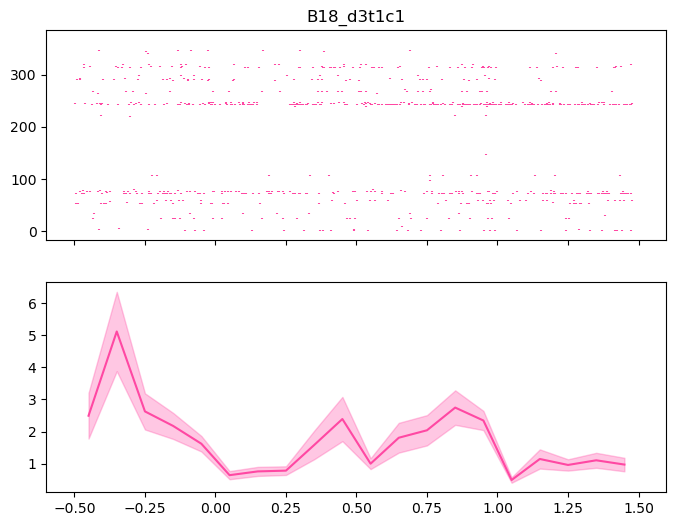

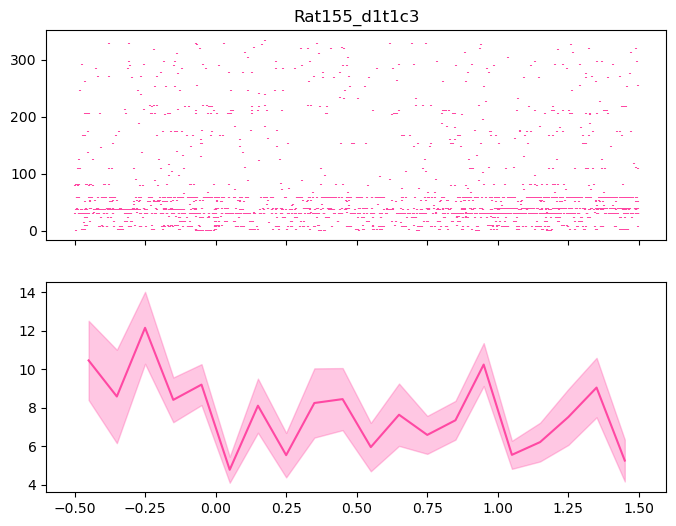

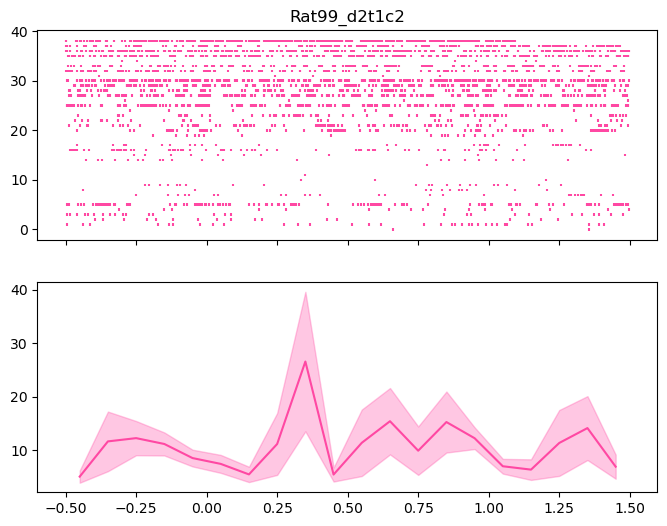

In [10]:
run_analysis(input_files, params)